In [2]:
from sklearn.model_selection import train_test_split
import pandas as pd

train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
y_train = train["Survived"]
train = train.drop(columns="Survived")

test.head()


,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [3]:
# Controlliamo se ci sono valori mancanti

print("Percentuale di valori mancanti in train")
print(train.isna().mean() * 100)



Percentuale di valori mancanti in train
PassengerId     0.000000
Pclass          0.000000
Name            0.000000
Sex             0.000000
Age            19.865320
SibSp           0.000000
Parch           0.000000
Ticket          0.000000
Fare            0.000000
Cabin          77.104377
Embarked        0.224467
dtype: float64


'Cabin, Ticket, e PassengerId' possiamo dropparli poiche' non contengono  informazioni rilevanti



In [4]:
cols_to_drop = ["Cabin","Ticket","PassengerId", "Name"]
train = train.drop(columns=cols_to_drop)
test = test.drop(columns=cols_to_drop)

In [5]:
print(train.head())
print(test.head())

   Pclass     Sex   Age  SibSp  Parch     Fare Embarked
0       3    male  22.0      1      0   7.2500        S
1       1  female  38.0      1      0  71.2833        C
2       3  female  26.0      0      0   7.9250        S
3       1  female  35.0      1      0  53.1000        S
4       3    male  35.0      0      0   8.0500        S
   Pclass     Sex   Age  SibSp  Parch     Fare Embarked
0       3    male  34.5      0      0   7.8292        Q
1       3  female  47.0      1      0   7.0000        S
2       2    male  62.0      0      0   9.6875        Q
3       3    male  27.0      0      0   8.6625        S
4       3  female  22.0      1      1  12.2875        S


In [6]:
X_train, X_val, y_train, y_val = train_test_split(train, y_train, stratify=y_train, test_size=0.05, random_state=42)

In [7]:
# effettuiamo una imputazione stratificata di Age per PClass e Sex

median_map = X_train.groupby(["Pclass","Sex"])["Age"].median()

train_age_imputed = X_train.set_index(["Pclass", "Sex"]).index.map(median_map)
test_age_imputed = test.set_index(["Pclass", "Sex"]).index.map(median_map)
val_age_imputed = X_val.set_index(["Pclass", "Sex"]).index.map(median_map)

train["Age"] = X_train["Age"].fillna(pd.Series(train_age_imputed, index=X_train.index))
test["Age"] = test["Age"].fillna(pd.Series(test_age_imputed, index=test.index))
X_val["Age"] = X_val["Age"].fillna(pd.Series(val_age_imputed, index=X_val.index))


In [8]:
print("Percentuale di valori mancanti in train")
print(X_train.isna().mean() * 100)

print("Percentuale di valori mancanti in test")
print(test.isna().mean() * 100)

Percentuale di valori mancanti in train
Pclass       0.000000
Sex          0.000000
Age         19.976359
SibSp        0.000000
Parch        0.000000
Fare         0.000000
Embarked     0.236407
dtype: float64
Percentuale di valori mancanti in test
Pclass      0.000000
Sex         0.000000
Age         0.000000
SibSp       0.000000
Parch       0.000000
Fare        0.239234
Embarked    0.000000
dtype: float64


In [9]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Pclass    891 non-null    int64  
 1   Sex       891 non-null    object 
 2   Age       846 non-null    float64
 3   SibSp     891 non-null    int64  
 4   Parch     891 non-null    int64  
 5   Fare      891 non-null    float64
 6   Embarked  889 non-null    object 
dtypes: float64(2), int64(3), object(2)
memory usage: 48.9+ KB


In [10]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

cat_features = X_train.select_dtypes(include=["bool","object","string"]).columns
num_features = X_train.select_dtypes(include=["number"]).columns

cat_pipeline = Pipeline(steps=[
    ("imp", SimpleImputer(strategy="most_frequent")),
    ("enc", OneHotEncoder(handle_unknown="ignore", sparse_output=False, drop='if_binary'))
])

num_pipeline = Pipeline(steps=[
    ("imp", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer(transformers=[
    ("cat", cat_pipeline, cat_features),
    ("num", num_pipeline, num_features)
])

preprocessor.set_output(transform="pandas")

train_processed = preprocessor.fit_transform(X_train,y_train)
test_processed = preprocessor.transform(test)
val_processed = preprocessor.transform(X_val)



In [11]:
print("Percentuale di valori mancanti in train")
print(train_processed.isnull().mean() * 100)

print("Percentuale di valori mancanti in test")
print(test_processed.isnull().mean() * 100)

Percentuale di valori mancanti in train
cat__Sex_male      0.0
cat__Embarked_C    0.0
cat__Embarked_Q    0.0
cat__Embarked_S    0.0
num__Pclass        0.0
num__Age           0.0
num__SibSp         0.0
num__Parch         0.0
num__Fare          0.0
dtype: float64
Percentuale di valori mancanti in test
cat__Sex_male      0.0
cat__Embarked_C    0.0
cat__Embarked_Q    0.0
cat__Embarked_S    0.0
num__Pclass        0.0
num__Age           0.0
num__SibSp         0.0
num__Parch         0.0
num__Fare          0.0
dtype: float64


In [12]:
import pandas as pd
from sklearn.feature_selection import SelectFromModel
from sklearn.svm import LinearSVC

# 1. Istanziamo LinearSVC con regolarizzazione L1
# Il parametro C controlla la sparsità: valori più piccoli di C eliminano più feature!
svm_l1 = LinearSVC(penalty='l1', dual=False, C=0.1, random_state=42)

# 2. Incapsuliamo il modello in SelectFromModel (metodo embedded)
selector = SelectFromModel(estimator=svm_l1)

# 3. Fit solo sul Training Set e trasformazione sui vari split (no Data Leakage)
X_train_selected = selector.fit_transform(train_processed, y_train)
X_test_selected = selector.transform(test_processed)
X_val_selected = selector.transform(val_processed)

# 4. Estrazione dei nomi delle feature selezionate
selected_features = selector.get_feature_names_out(input_features=train_processed.columns)

print(f"Features selezionate ({len(selected_features)}): {list(selected_features)}")
print(f"Nuova forma di X_train: {X_train_selected.shape}")

Features selezionate (8): ['cat__Sex_male', 'cat__Embarked_C', 'cat__Embarked_Q', 'num__Pclass', 'num__Age', 'num__SibSp', 'num__Parch', 'num__Fare']
Nuova forma di X_train: (846, 8)


In [13]:
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.ensemble import RandomForestClassifier

param_grid = {
    "n_estimators" : [100,150],
    "min_samples_split" : [2,3],
    "criterion" : ["gini", "entropy"]
}
cv = KFold(n_splits=6, shuffle=True, random_state=42)
rfc = RandomForestClassifier(random_state=42)
grid = GridSearchCV(estimator=rfc, cv=cv, param_grid=param_grid, n_jobs=-1,scoring="accuracy")

grid.fit(X_train_selected, y_train)


,estimator,RandomForestC...ndom_state=42)
,param_grid,"{'criterion': ['gini', 'entropy'], 'min_samples_split': [2, 3], 'n_estimators': [100, 150]}"
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,KFold(n_split... shuffle=True)
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,100


In [14]:
best_estimator = grid.best_estimator_
best_params = grid.best_params_
best_score = grid.best_score_

print(f"Miglior modello: {best_estimator}")
print(f"Migliori parametri:{best_params}")
print(f"Miglior score in CV: {best_score}")

# predict sulle feature selezionate
y_rfc_pred = best_estimator.predict(X_val_selected)
y_rfc_prob = best_estimator.predict_proba(X_val_selected)

from sklearn.metrics import accuracy_score, roc_auc_score

rfc_acc = accuracy_score(y_val, y_rfc_pred)
rfc_auc = roc_auc_score(y_val, y_rfc_prob[:,1])

print(f"Acc: {rfc_acc}, AUC: {rfc_auc}")

Miglior modello: RandomForestClassifier(min_samples_split=3, random_state=42)
Migliori parametri:{'criterion': 'gini', 'min_samples_split': 3, 'n_estimators': 100}
Miglior score in CV: 0.8297872340425533
Acc: 0.7555555555555555, AUC: 0.8046218487394958


Test Configurazione 1:{'filters_num': 16, 'kernel_size': 2, 'lr': 0.01}


Epoch    1: 100%|██████████| 14/14 [00:00<00:00, 322.34it/s]


Train loss: 0.6388
Validation loss: 0.5990
Test loss: 0.5990 Accuracy:   0.69
Metrics:



Epoch    2: 100%|██████████| 14/14 [00:00<00:00, 166.43it/s]


Train loss: 0.5577
Validation loss: 0.5681
Test loss: 0.5681 Accuracy:   0.73
Metrics:



Epoch    3: 100%|██████████| 14/14 [00:00<00:00, 377.10it/s]


... (150 outputs left out)

Train loss: 0.4747
Validation loss: 0.5527
Test loss: 0.5527 Accuracy:   0.73
Metrics:



Epoch   19: 100%|██████████| 14/14 [00:00<00:00, 315.67it/s]


Train loss: 0.4419
Validation loss: 0.5738
Test loss: 0.5738 Accuracy:   0.73
Metrics:

--> Config 4 Risultati: Accuracy = 0.7333 | ROC-AUC = 0.7962

MIGLIOR CONFIGURAZIONE CNN:
{'filters_num': 32, 'kernel_size': 2, 'lr': 0.001}
Accuracy (Validation): 0.7556
ROC-AUC  (Validation): 0.8456


ValueError: x, y, and format string must not be None

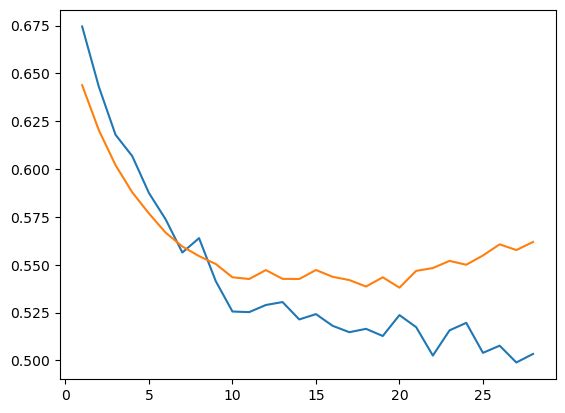

In [18]:
import torch 
import torchnn as tnn
from torch import nn
from torch.utils.data import Dataset, DataLoader
import numpy as np

class TitanicData(Dataset):
    def __init__(self,X,y):
        self.X = torch.tensor(np.array(X), dtype=torch.float32).unsqueeze(1)
        self.y = torch.tensor(np.array(y), dtype=torch.long)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, index):
        return self.X[index], self.y[index]

train_data = TitanicData(X_train_selected, y_train)
val_data = TitanicData(X_val_selected, y_val)

train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
val_loader = DataLoader(val_data, batch_size=64, shuffle=False)

class TitanicNet(nn.Module):
    def __init__(self, filters_num=32, kernel_size=32):
        super().__init__()

        # Layer CNN
        self.conv = nn.Sequential(
            nn.Conv1d(in_channels=1, out_channels=filters_num, kernel_size=kernel_size),
            nn.BatchNorm1d(filters_num),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),
            nn.Dropout(0.2)
        )

        self.gap = nn.AdaptiveAvgPool1d(1)

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(filters_num, 32),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(32,2)
        )

    def forward(self,x):
        x = self.conv(x)
        x = self.gap(x)

        logits = self.classifier(x)
        return logits

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
loss_fn = nn.CrossEntropyLoss()

# griglia di iperparametri

param_grid_cnn = [
    {'filters_num':16, 'kernel_size' : 2 , 'lr' : 0.01},
    {'filters_num':32, 'kernel_size' : 2 , 'lr' : 0.001},
    {'filters_num':32, 'kernel_size' : 3 , 'lr' : 0.001},
    {'filters_num':64, 'kernel_size' : 3 , 'lr' : 0.005}
]

best_auc = 0.0
best_model_info = {}

import torch.optim as optim

for i, params in enumerate(param_grid_cnn):
    print(f"Test Configurazione {i+1}:{params}")

    model = TitanicNet(
        filters_num=params['filters_num'],
        kernel_size=params['kernel_size']
    ).to(device)

    optimizer = optim.Adam(model.parameters(), lr=params['lr'], weight_decay=1e-4)
    early_stopping = tnn.EarlyStopping(patience=10, min_delta=0.001)

    # Addestramento della configurazione corrente
    train_loss, validation_loss, _, val_acc_list, _ = tnn.train_test(
        model=model,
        optimizer=optimizer,
        device=device,
        train_dataloader=train_loader,
        test_dataloader=val_loader,    # Valutazione usata epoca per epoca
        val_dataloader=val_loader,     # Monitorato dall'early stopping
        train_loss_fn=loss_fn,
        test_loss_fn=loss_fn,
        early_stopping=early_stopping,
        epochs=40,
        metrics=[]
    )

    # Calcolo delle probabilità su val set  per ROC-AUC
    model.eval()
    nn_val_pred, nn_val_prob,nn_true = [],[],[]
    with torch.no_grad():
        for X_batch,y_batch in val_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            logits = model(X_batch)
            probs = torch.softmax(logits, 1)[:,1] #Probabilità classe positiva
            nn_true.extend(y_batch.numpy())
            nn_val_prob.extend(probs.cpu().numpy())
            nn_val_pred.extend(logits.cpu().numpy())

    current_auc = roc_auc_score(nn_true, nn_val_prob)
    current_acc = val_acc_list[-1] if len(val_acc_list) > 0 else 0.0

    print(f"--> Config {i+1} Risultati: Accuracy = {current_acc:.4f} | ROC-AUC = {current_auc:.4f}")

    # Salvataggio del best model in base all'AUC

    if current_auc > best_auc:
        best_auc=current_auc
        best_model_info={
            'params' : params,
            'model_state' : model.state_dict(),
            'accuracy' : current_acc,
            'auc' : current_auc,
            'train_loss' : train_loss,
            'val_loss' : validation_loss
        }

print("\n" + "="*50)
print("MIGLIOR CONFIGURAZIONE CNN:")
print(best_model_info['params'])
print(f"Accuracy (Validation): {best_model_info['accuracy']:.4f}")
print(f"ROC-AUC  (Validation): {best_model_info['auc']:.4f}")

# Plot delle loss della miglior configurazione
tnn.displayLosses(
    train_loss=best_model_info['train_loss'], 
    test_loss=None, 
    validation_loss=best_model_info['val_loss']
)

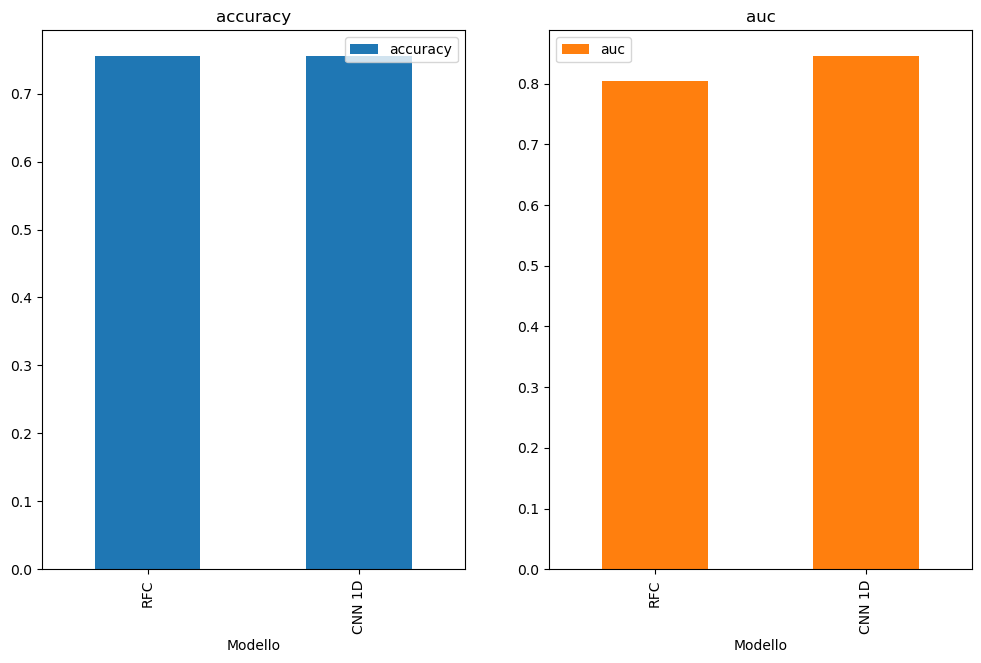


=== TABELLA COMPARATIVA FINALE  ===
Modello  accuracy      auc
    RFC  0.755556 0.804622
 CNN 1D  0.755556 0.845588


In [23]:
import pandas as pd

confronto_df = pd.DataFrame({
    'Modello' : ['RFC', 'CNN 1D'],
    'accuracy' : [rfc_acc, best_model_info['accuracy']],
    'auc' : [rfc_auc, best_model_info['auc']]
})

import matplotlib.pyplot as plt

confronto_df.plot(subplots=True, x='Modello', kind='bar', sharex=True, layout=(1,2), figsize=(12,7))
plt.legend()
plt.show()

print("\n=== TABELLA COMPARATIVA FINALE  ===")
print(confronto_df.to_string(index=False))